# WildChat story responses: Jev vs Qwen3Guard, then Jev vs WildChat's own flags

**Questions.** (1) Can TypeSafe's Jev stand in for Qwen3Guard-Gen-4B as a response safety classifier? (2) On every
English first-turn story pair from one WildChat-4.8M-Full shard, where do Jev and WildChat's `toxic` flag disagree,
especially stories WildChat calls safe? (3) What kinds of prompts sit in each class?

**Data.** `data/wildchat/` (gitignored), built by the helper scripts:
- `response_pool.parquet`: 5,238 English first-turn story pairs from shard `train-00000` (pinned revision), with
  WildChat's per-message flags. `helper_scripts/wildchat_response_sample.py`.
- `response_sample.jsonl`: the seeded 100-pair head-to-head (50 WildChat-safe, 50 with a toxic-flagged response).
- Labels: `qwen_response_labels.jsonl` (`guard_classify.py`), `jev_labels.jsonl`, `jev_pool_labels.jsonl` and
  `jev_topics.jsonl` (`jev_classify.py`, which reads the API key from the gitignored `.env`).

Run from the project root:
`uv run --no-project --with jupyterlab,pandas,pyarrow,matplotlib jupyter lab`.
Some prompts and responses are sexually explicit or violent; text is only printed in section 5.

In [1]:
import json
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / "helper_scripts" / "jev_classify.py").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Run this notebook from inside the project folder.")
    ROOT = ROOT.parent
WC = ROOT / "data" / "wildchat"
LABELS = ["Safe", "Controversial", "Unsafe"]

# Fixed colours per source (validated palette): the same entity keeps its colour in every figure.
COLOR = {"Qwen3Guard": "#2a78d6", "Jev": "#eb6834", "WildChat": "#1baf7a"}
INK, MUTED = "#0b0b0b", "#898781"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e8e7e3", "axes.axisbelow": True,
                     "font.size": 10})
pd.set_option("display.width", 200)


def kappa(a, b):
    """Cohen's kappa: agreement corrected for chance (0 = chance, 0.6-0.8 substantial, >0.8 near-perfect)."""
    po = (a == b).mean()
    pe = sum(a.eq(c).mean() * b.eq(c).mean() for c in set(a) | set(b))
    return (po - pe) / (1 - pe)


def snippet(text, n=140):
    return " ".join(str(text).split())[:n]

## 1. Jev vs Qwen3Guard on the same 100 responses

Both classifiers judge **only the assistant's reply**, given the prompt, using Qwen3Guard's own policy text, and
both see identical (identically truncated) text. Agreement with Qwen3Guard is not accuracy, but Qwen3Guard is the
classifier we already trusted, so this is the check that matters for swapping it out.

In [2]:
sample = pd.read_json(WC / "response_sample.jsonl", lines=True)
qwen = pd.read_json(WC / "qwen_response_labels.jsonl", lines=True)
jev = pd.read_json(WC / "jev_labels.jsonl", lines=True)
h2h = (sample[["key", "group"]]
       .merge(qwen[["key", "safety"]].rename(columns={"safety": "Qwen3Guard"}), on="key")
       .merge(jev[["key", "safety", "model"]].rename(columns={"safety": "Jev"}), on="key"))

q, j = h2h["Qwen3Guard"], h2h["Jev"]
display(pd.DataFrame({
    "agree %": [100 * (q == j).mean(), 100 * (q.eq("Safe") == j.eq("Safe")).mean()],
    "Cohen's kappa": [kappa(q, j), kappa(q.eq("Safe"), j.eq("Safe"))],
}, index=["3-way (Safe / Controversial / Unsafe)", "Safe vs not safe"]).round(2))
print(f"n = {len(h2h)}, Jev version {h2h.model.iloc[0]}")
print("Confusion matrix (rows Qwen3Guard, columns Jev):")
display(pd.crosstab(q, j).reindex(index=LABELS, columns=LABELS, fill_value=0))

,agree %,Cohen's kappa
3-way (Safe / Controversial / Unsafe),85.0,0.70
Safe vs not safe,92.0,0.83


n = 100, Jev version jev-1.14.0
Confusion matrix (rows Qwen3Guard, columns Jev):


Jev,Safe,Controversial,Unsafe
Qwen3Guard,,,
Safe,58,0,7
Controversial,0,0,7
Unsafe,1,0,27


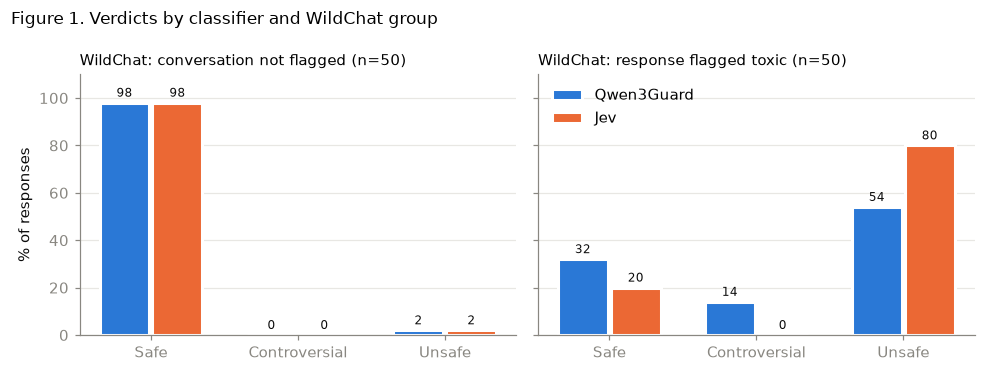

In [3]:
groups = {"wildchat_safe": "WildChat: conversation not flagged", "wildchat_toxic_response": "WildChat: response flagged toxic"}
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for ax, (g, title) in zip(axes, groups.items()):
    d = h2h[h2h.group == g]
    for i, model in enumerate(["Qwen3Guard", "Jev"]):
        pct = 100 * d[model].value_counts(normalize=True).reindex(LABELS, fill_value=0)
        x = [k + (i - 0.5) * 0.36 for k in range(len(LABELS))]
        bars = ax.bar(x, pct, width=0.34, color=COLOR[model], label=model, edgecolor="white", linewidth=2)
        ax.bar_label(bars, fmt="%.0f", fontsize=8, color=INK, padding=2)
    ax.set_xticks(range(len(LABELS)), LABELS)
    ax.set_title(f"{title} (n={len(d)})", fontsize=10, loc="left")
axes[0].set_ylabel("% of responses")
axes[0].set_ylim(0, 110)
axes[1].legend(frameon=False, loc="upper left")
fig.suptitle("Figure 1. Verdicts by classifier and WildChat group", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

**Reading Figure 1.** On WildChat-safe stories the two classifiers agree almost exactly. On WildChat-flagged
responses they differ mainly because **Jev almost never answers "Controversial"** (never in this sample; its highest
probability for that label was 0.42): what Qwen3Guard calls Controversial, Jev calls Unsafe. On the Safe-vs-not cut, the one
that matters for "are the safe stories safe?", agreement is near-perfect. So below, Jev's labels are used as
**Safe vs not safe** ("unsafe" = Unsafe or Controversial), and its speed (4 s vs 11 min per 100 pairs) is what makes section 2 possible.

## 2. Label every pair in the shard with Jev

Two passes over all 5,238 pairs: **safety** of the response (same questions as section 1) and **topic** of the
prompt (one topic from a fixed list, plus fan-fiction and jailbreak probabilities; the list and why it looks like
this are in `helper_scripts/jev_classify.py`). Both passes resume, so rerunning skips pairs already labelled.
Cost is roughly 2K input tokens per safety call (~$0.45 for the shard at $0.042 per million).

In [4]:
pool = pd.read_parquet(WC / "response_pool.parquet")
POOL_JSONL = WC / "response_pool.jsonl"
if not POOL_JSONL.exists():
    pool[["key", "prompt", "response"]].to_json(POOL_JSONL, orient="records", lines=True, force_ascii=False)

script = str(ROOT / "helper_scripts" / "jev_classify.py")
for task, out in [("safety", "jev_pool_labels.jsonl"), ("topic", "jev_topics.jsonl")]:
    r = subprocess.run(["uv", "run", "--quiet", script, str(POOL_JSONL), "--task", task, "--out", str(WC / out),
                        "--workers", "16"], capture_output=True, text=True, cwd=ROOT)
    print(task, "|", r.stdout.strip().splitlines()[0] if r.stdout.strip() else "", "|", r.stderr.strip()[-300:])

safety = pd.read_json(WC / "jev_pool_labels.jsonl", lines=True)
topics = pd.read_json(WC / "jev_topics.jsonl", lines=True)
df = (pool.merge(safety[["key", "safety", "category", "safety_confidence"]].rename(columns={"category": "jev_category"}),
                 on="key")
          .merge(topics[["key", "topic", "topic_confidence", "fan_fiction", "jailbreak"]], on="key"))
df["jev_unsafe"] = df.safety != "Safe"
df["wc_bucket"] = pd.Categorical(
    df.response_toxic.map({True: "Response flagged"}).fillna(
        df.conversation_toxic.map({True: "Only prompt flagged", False: "Not flagged"})),
    ["Not flagged", "Only prompt flagged", "Response flagged"])
print(f"{len(df):,} of {len(pool):,} pairs have both labels; Jev labels used: {df.safety.value_counts().to_dict()}")

# The keyword story filter also catches code, essays and agent prompts ("script", "chapter", "narrative"), so the
# comparisons below keep only prompts Jev identifies as fiction requests.
fic = df[df.topic != "Not a fiction request"]
nonfic = (df.topic == "Not a fiction request").groupby(df.wc_bucket, observed=True).mean().mul(100).round(1)
print(f"Fiction requests: {len(fic):,} of {len(df):,} ({100 * len(fic) / len(df):.0f}%). "
      f"Share NOT fiction by WildChat bucket (%): {nonfic.to_dict()}")

safety | 5238 already labelled, 0 to go -> /Users/mihirjoshi/AI Research - Cornell/data/wildchat/jev_pool_labels.jsonl | 
topic | 5238 already labelled, 0 to go -> /Users/mihirjoshi/AI Research - Cornell/data/wildchat/jev_topics.jsonl | 
5,238 of 5,238 pairs have both labels; Jev labels used: {'Safe': 3110, 'Unsafe': 2055, 'Controversial': 73}


Fiction requests: 3,625 of 5,238 (69%). Share NOT fiction by WildChat bucket (%): {'Not flagged': 66.1, 'Only prompt flagged': 19.9, 'Response flagged': 3.5}


## 3. Jev vs WildChat's flags

WildChat flags a message when the 2023 OpenAI moderation endpoint or Detoxify fires on it. "Response flagged" is
the flag on the assistant reply itself; "Only prompt flagged" means the conversation is marked toxic because of the
user's message, while the reply passed. Fiction requests only (see the count above).

safety,Safe,Controversial,Unsafe,n,Jev unsafe %
wc_bucket,,,,,
Not flagged,531,33,106,670,20.7
Only prompt flagged,628,16,307,951,34.0
Response flagged,392,12,1600,2004,80.4


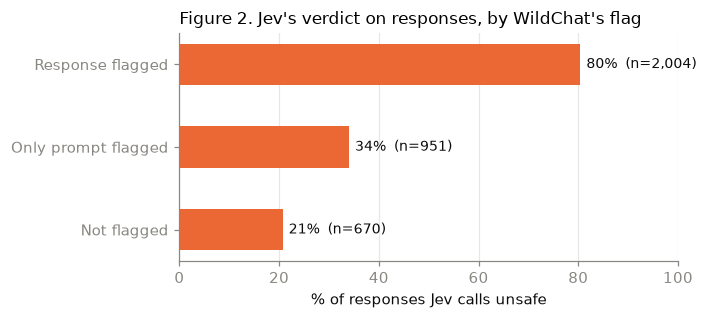

In [5]:
tab = pd.crosstab(fic.wc_bucket, fic.safety).reindex(columns=[l for l in LABELS if l in set(df.safety)])
tab["n"] = tab.sum(axis=1)
tab["Jev unsafe %"] = (100 * (tab.n - tab["Safe"]) / tab.n).round(1)
display(tab)

fig, ax = plt.subplots(figsize=(6.5, 3))
bars = ax.barh(tab.index.astype(str), tab["Jev unsafe %"], color=COLOR["Jev"], height=0.5)
ax.bar_label(bars, labels=[f"{p:.0f}%  (n={n:,})" for p, n in zip(tab["Jev unsafe %"], tab.n)], padding=4,
             fontsize=9, color=INK)
ax.set_xlim(0, 100)
ax.set_xlabel("% of responses Jev calls unsafe")
ax.grid(axis="x", color="#e8e7e3"); ax.grid(axis="y", visible=False)
ax.set_title("Figure 2. Jev's verdict on responses, by WildChat's flag", loc="left", fontsize=11)
fig.tight_layout()
plt.show()

In [6]:
missed = fic[(fic.wc_bucket == "Not flagged") & fic.jev_unsafe]
over = fic[(fic.wc_bucket == "Response flagged") & ~fic.jev_unsafe]
print(f"WildChat-safe but Jev-unsafe: {len(missed)} of {(fic.wc_bucket == 'Not flagged').sum():,}. Jev's categories:")
display(missed.jev_category.value_counts().to_frame("n"))
print(f"WildChat-flagged response but Jev-safe: {len(over)} of {(fic.wc_bucket == 'Response flagged').sum():,}. "
      "OpenAI moderation categories that fired on the response:")
display(over.response_openai_categories.explode().value_counts().to_frame("n"))

WildChat-safe but Jev-unsafe: 139 of 670. Jev's categories:


,n
jev_category,
Sexual Content or Sexual Acts,63
None,27
Politically Sensitive Topics,26
Unethical Acts,12
Non-violent Illegal Acts,8
Violent,3


WildChat-flagged response but Jev-safe: 392 of 2,004. OpenAI moderation categories that fired on the response:


,n
response_openai_categories,
violence,335
harassment,11
sexual,11
violence_graphic,7
self-harm,3
self_harm,3


## 4. What kinds of prompts are in each class?

Jev assigns each prompt one topic. Two checks before reading the breakdown: how big **"Other"** is (if large, the
topic list misses real themes) and how confident Jev is. Non-fiction prompts are already excluded.

In [7]:
counts = df.topic.value_counts()
print(f"Other: {100 * counts.get('Other', 0) / len(df):.1f}%   |   Not a fiction request: "
      f"{100 * counts.get('Not a fiction request', 0) / len(df):.1f}%   |   median topic confidence "
      f"{df.topic_confidence.median():.2f}")

by = fic.groupby("topic").agg(
    n=("key", "size"),
    fan_fiction_pct=("fan_fiction", lambda s: 100 * (s > 0.5).mean()),
    jailbreak_pct=("jailbreak", lambda s: 100 * (s > 0.5).mean()),
    wildchat_flagged_pct=("response_toxic", lambda s: 100 * s.mean()),
    jev_unsafe_pct=("jev_unsafe", lambda s: 100 * s.mean()),
)
by["missed_by_wildchat_pct"] = 100 * fic.assign(m=(fic.wc_bucket == "Not flagged") & fic.jev_unsafe).groupby("topic").m.mean()
by["overflagged_by_wildchat_pct"] = 100 * fic.assign(m=fic.response_toxic & ~fic.jev_unsafe).groupby("topic").m.mean()
by = by.sort_values("n", ascending=False).round(1)
display(by)

Other: 1.1%   |   Not a fiction request: 30.8%   |   median topic confidence 0.93


,n,fan_fiction_pct,jailbreak_pct,wildchat_flagged_pct,jev_unsafe_pct,missed_by_wildchat_pct,overflagged_by_wildchat_pct
topic,,,,,,,
Fetish or body-focused,1111,17.1,37.6,52.8,70.6,4.1,7.7
Erotic or sexually explicit,1107,30.0,58.2,77.9,82.7,2.1,1.5
"Adventure, fantasy or sci-fi",578,56.2,10.9,38.9,23.2,5.7,24.6
Comedy or wholesome,218,39.9,6.4,24.3,11.5,0.5,14.2
"Violence, combat or crime",189,31.7,29.6,71.4,66.7,6.3,16.4
Drama or everyday life,146,17.1,19.9,30.8,13.7,5.5,24.0
Horror or disturbing,134,30.6,5.2,56.0,28.4,0.0,29.9
Romance (non-explicit),84,33.3,11.9,15.5,17.9,7.1,8.3
Other,58,3.4,1.7,15.5,29.3,19.0,6.9


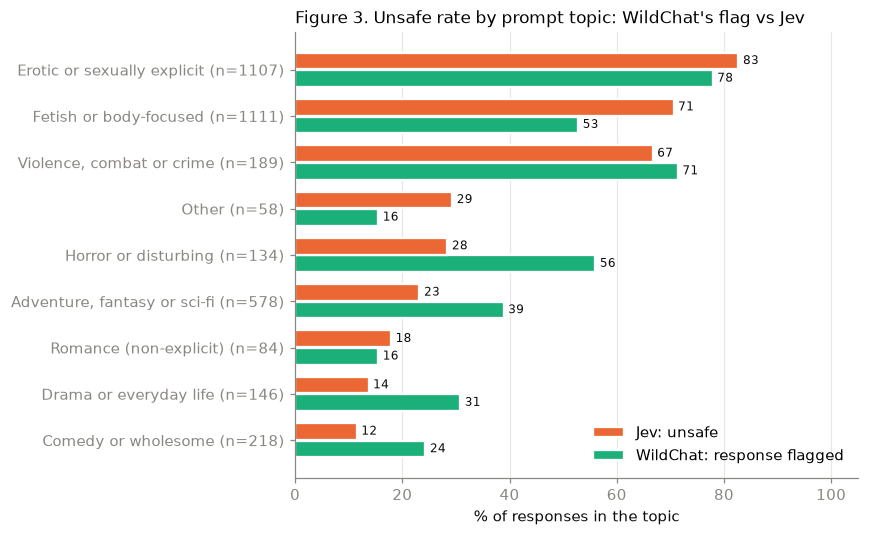

In [8]:
order = by.sort_values("jev_unsafe_pct").index
fig, ax = plt.subplots(figsize=(8, 0.42 * len(order) + 1.2))
y = range(len(order))
for i, (col, name) in enumerate([("wildchat_flagged_pct", "WildChat"), ("jev_unsafe_pct", "Jev")]):
    yy = [k + (i - 0.5) * 0.38 for k in y]
    bars = ax.barh(yy, by.loc[order, col], height=0.36, color=COLOR[name], edgecolor="white", linewidth=1.5,
                   label={"WildChat": "WildChat: response flagged", "Jev": "Jev: unsafe"}[name])
    ax.bar_label(bars, fmt="%.0f", fontsize=8, color=INK, padding=3)
ax.set_yticks(list(y), [f"{t} (n={by.loc[t, 'n']:.0f})" for t in order])
ax.set_xlim(0, 105)
ax.set_xlabel("% of responses in the topic")
ax.grid(axis="x", color="#e8e7e3"); ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right", reverse=True)  # match the bar order (Jev on top)
ax.set_title("Figure 3. Unsafe rate by prompt topic: WildChat's flag vs Jev", loc="left", fontsize=11)
fig.tight_layout()
plt.show()

In [9]:
jb = fic.assign(jailbreak_prompt=fic.jailbreak > 0.5).groupby("jailbreak_prompt").agg(
    n=("key", "size"), jev_unsafe_pct=("jev_unsafe", lambda s: 100 * s.mean()),
    wildchat_flagged_pct=("response_toxic", lambda s: 100 * s.mean())).round(1)
display(jb)

,n,jev_unsafe_pct,wildchat_flagged_pct
jailbreak_prompt,,,
False,2383,48.2,52.5
True,1242,74.6,60.7


## 5. Read examples

Two prompt openings per topic for each kind of disagreement. Text may be explicit. Set `SHOW_TEXT = False` to skip.

In [ ]:
SHOW_TEXT = True
if SHOW_TEXT:
    for topic in by.index:
        d = fic[fic.topic == topic]
        for label, mask in [("WildChat safe, Jev unsafe", (d.wc_bucket == "Not flagged") & d.jev_unsafe),
                            ("WildChat flagged, Jev safe", d.response_toxic & ~d.jev_unsafe)]:
            ex = d[mask]
            if len(ex):
                print(f"--- {topic} | {label} ({len(ex)})")
                for p in ex.sample(min(2, len(ex)), random_state=0).prompt:
                    print("   ", snippet(p))

## 6. Notes

Results for shard `train-00000` (5,238 pairs; Jev `jev-1.14.0`; labelled 2026-11-17).

1. **The keyword story filter is leaky.** 31% of the "story" prompts are not fiction requests (code, essays,
   academic rewriting, agent instructions), and that rises to **66% of the pairs WildChat left unflagged**. Any
   "WildChat-safe stories" rate built on the keyword filter is mostly about non-stories; notebook 03 uses the same
   filter. Jev's topic label is a cheap fix.
2. **Stories WildChat calls safe are not all safe.** Among fiction requests with no WildChat flag, Jev calls **21%
   (139 of 670)** of responses unsafe, mostly sexual content (63) and politically sensitive (26). 27 of the 139 have
   category "None", which is internally inconsistent: read those first. This is the headline number, and it rests
   on Jev alone; validate it (next steps) before reporting it.
3. **WildChat over-flags violence in fiction.** Jev calls 392 of 2,004 flagged responses safe, and 335 of those were
   flagged only by OpenAI moderation's `violence` category. Over-flagging is highest for horror (30% of the topic),
   adventure/fantasy/sci-fi (25%) and drama (24%), where violence is part of the plot.
4. **A flagged prompt often gets an unsafe reply.** When only the user's message was flagged, Jev still calls 34%
   of the replies unsafe: the model frequently complied.
5. **What the unsafe stories are.** Erotic (1,107) and fetish/body-focused (1,111) requests make up 61% of fiction
   prompts and have the highest unsafe rates (83% and 71%). Fetish/body-focused is where Jev and WildChat disagree
   most in the unsafe direction (71% vs 53%): non-explicit fixation content that 2023 moderation didn't catch.
   **34% of fiction prompts are jailbreak attempts**, and their replies are unsafe 75% of the time vs 48% otherwise.
6. **The topic list fits.** "Other" is 1.1% and median topic confidence is 0.93.

**Caveats.** One shard of 127. Jev was checked against Qwen3Guard on only 100 pairs and against human judgment on
none. Topics are Jev's single best guess per prompt.

**Next steps.** (a) Validate finding 2: run Qwen3Guard on the 139 (~15 min) and hand-label ~50 of them. (b) Use
Jev's topic label to filter stories in notebook 03. (c) Scale to more shards with
`wildchat_response_sample.py --files N` (a few dollars for all 127).